# 01 · Dataset exploration
GEO **GSE109169**: 25 matched pairs of breast tumor and *adjacent* normal tissue, Affymetrix Human Exon 1.0 ST
(GPL5175), RMA-normalized. This notebook inspects samples, patients and the expression scale.
Run `python -m oncogene.cli all` first.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
from oncogene.config import Paths, load_config
from oncogene.data.load import load_processed
paths, cfg = Paths(), load_config()
ds = load_processed(paths)
X, meta, ann = ds.X, ds.meta, ds.annotation
M = paths.metrics
print(X.shape, meta.shape)

(50, 17868) (50, 9)


## Sample metadata
Labels come from the `tissue` characteristic and are cross-checked against sample titles.

In [2]:
meta.head(10)

,title,tissue_raw,patient_id,age_years,cancer_stage,sex,platform_id,label,tissue_type
sample_id,,,,,,,,,
GSM2934481,2102-Normal,breast tumor adjacent normal tissue,2102,46,IIIA,female,GPL5175,0,Adjacent normal
GSM2934482,2102-Tumor,breast cancer tissue,2102,46,IIIA,female,GPL5175,1,Tumor
GSM2934483,2110-Normal,breast tumor adjacent normal tissue,2110,43,IIIC,female,GPL5175,0,Adjacent normal
GSM2934484,2110-Tumor,breast cancer tissue,2110,43,IIIC,female,GPL5175,1,Tumor
GSM2934485,2146-Normal,breast tumor adjacent normal tissue,2146,54,IIA,female,GPL5175,0,Adjacent normal
GSM2934486,2146-Tumor,breast cancer tissue,2146,54,IIA,female,GPL5175,1,Tumor
GSM2934487,2181-Normal,breast tumor adjacent normal tissue,2181,53,I,female,GPL5175,0,Adjacent normal
GSM2934488,2181-Tumor,breast cancer tissue,2181,53,I,female,GPL5175,1,Tumor
GSM2934489,2190-Normal,breast tumor adjacent normal tissue,2190,44,I,female,GPL5175,0,Adjacent normal


In [3]:
meta.groupby('tissue_type').size(), meta['patient_id'].nunique(), meta.drop_duplicates('patient_id')['cancer_stage'].value_counts()

(tissue_type
 Adjacent normal    25
 Tumor              25
 dtype: int64,
 25,
 cancer_stage
 IIA     8
 IIIA    7
 I       6
 IIB     3
 IIIC    1
 Name: count, dtype: int64)

## Expression scale
Values range ~1.5–14, consistent with log2 RMA output, so **no additional log transform** is applied.

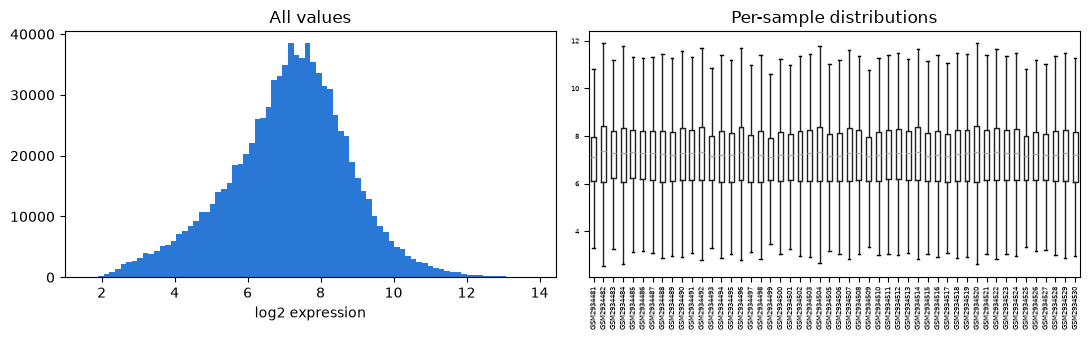

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(X.values.ravel(), bins=80, color='#2a78d6'); ax[0].set_xlabel('log2 expression'); ax[0].set_title('All values')
X.T.boxplot(ax=ax[1], showfliers=False, grid=False, rot=90, fontsize=5); ax[1].set_title('Per-sample distributions')
plt.tight_layout()

## Exploratory PCA (all samples — descriptive only)

Text(0.5, 1.0, 'blue = adjacent normal, orange = tumor')

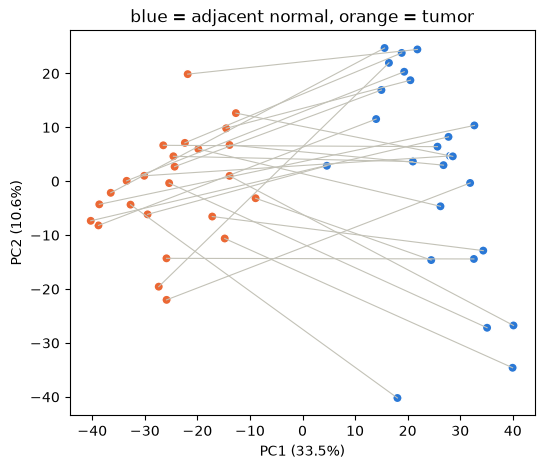

In [5]:
from oncogene.analysis.exploratory import exploratory_pca
pca_df, evr = exploratory_pca(X, meta)
colors = pca_df['label'].map({0: '#2a78d6', 1: '#eb6834'})
fig, ax = plt.subplots(figsize=(6, 5))
for _, g in pca_df.groupby('patient_id'): ax.plot(g.PC1, g.PC2, color='#c3c2b7', lw=.8)
ax.scatter(pca_df.PC1, pca_df.PC2, c=colors, s=45, edgecolor='white')
ax.set_xlabel(f'PC1 ({evr[0]:.1%})'); ax.set_ylabel(f'PC2 ({evr[1]:.1%})'); ax.set_title('blue = adjacent normal, orange = tumor')

In [6]:
from scipy.stats import mannwhitneyu
print('PC1 tumor vs normal Mann-Whitney p =', mannwhitneyu(pca_df.loc[pca_df.label==1,'PC1'], pca_df.loc[pca_df.label==0,'PC1']).pvalue)

PC1 tumor vs normal Mann-Whitney p = 1.4156562248495535e-09


## Outlier screen and composition scores

In [7]:
pd.read_csv(M/'outlier_screen.csv', index_col=0).sort_values('robust_z').head(10)

,mean_within_group_corr,patient_id,tissue_type,robust_z,flagged
sample_id,,,,,
GSM2934516,0.618413,2972,Tumor,-6.246339,True
GSM2934490,0.623710,2190,Tumor,-5.979166,True
GSM2934517,0.688662,2985,Adjacent normal,-4.219710,True
GSM2934496,0.660905,2353,Tumor,-4.102999,True
GSM2934502,0.674890,2451,Tumor,-3.397534,True
GSM2934498,0.686351,2365,Tumor,-2.819454,True
GSM2934515,0.745177,2972,Adjacent normal,-2.709675,True
GSM2934488,0.715045,2181,Tumor,-1.372080,False
GSM2934507,0.803664,2780,Adjacent normal,-1.146919,False


In [8]:
pd.read_csv(M/'marker_scores.csv', index_col=0).groupby('tissue_type').mean(numeric_only=True)

,patient_id,adipocyte_score,proliferation_score,myoepithelial_basal_score
tissue_type,,,,
Adjacent normal,2677.4,0.758488,-0.767038,0.655217
Tumor,2677.4,-0.758488,0.767038,-0.655217
